In [49]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [50]:
comment = "#"

In [51]:
df = pd.read_csv("exoplanet_data.csv", sep=",", comment="#")

In [52]:
df.shape

(599, 92)

599 rows x 92 columns 

In [53]:
df.columns

Index(['pl_name', 'hostname', 'default_flag', 'sy_snum', 'sy_pnum',
       'discoverymethod', 'disc_year', 'disc_facility', 'soltype',
       'pl_controv_flag', 'pl_refname', 'pl_orbper', 'pl_orbpererr1',
       'pl_orbpererr2', 'pl_orbperlim', 'pl_orbsmax', 'pl_orbsmaxerr1',
       'pl_orbsmaxerr2', 'pl_orbsmaxlim', 'pl_rade', 'pl_radeerr1',
       'pl_radeerr2', 'pl_radelim', 'pl_radj', 'pl_radjerr1', 'pl_radjerr2',
       'pl_radjlim', 'pl_bmasse', 'pl_bmasseerr1', 'pl_bmasseerr2',
       'pl_bmasselim', 'pl_bmassj', 'pl_bmassjerr1', 'pl_bmassjerr2',
       'pl_bmassjlim', 'pl_bmassprov', 'pl_orbeccen', 'pl_orbeccenerr1',
       'pl_orbeccenerr2', 'pl_orbeccenlim', 'pl_insol', 'pl_insolerr1',
       'pl_insolerr2', 'pl_insollim', 'pl_eqt', 'pl_eqterr1', 'pl_eqterr2',
       'pl_eqtlim', 'ttv_flag', 'st_refname', 'st_spectype', 'st_teff',
       'st_tefferr1', 'st_tefferr2', 'st_tefflim', 'st_rad', 'st_raderr1',
       'st_raderr2', 'st_radlim', 'st_mass', 'st_masserr1', 'st_masserr2

No clue:
- pl_orbeccenerr2
- pl_orbperlim
- pl_insollim
- st_loggerr1
- sy_kmagerr1


- Planet Name: 'pl_name', string, name of planet
- Host Name: 'hostname', string, name of host star
- Discovery Method: 'discoverymethod', string, method used to discover exoplanet
- Spectral Type: 'st_spectype', string, Spectral class of star
- Equilibrium Temperature [K]: 'pl_eqt
', float, "the temperature at which a system, planet, or body absorbs and emits energy at equal rates"
- Planet Mass or Mass*sin(i) [Jupiter Mass]: 'pl_bmassj', float, planets mass in units of Jupiter mass.



In [54]:
small_df = df[[
    'pl_name',
    'hostname',
    'discoverymethod',
    'st_spectype',
    'pl_eqt',
    'pl_bmassj'
]]

In [55]:
small_df = small_df.dropna()

In [56]:
small_df.shape

(77, 6)

77 rows x 6 columns

In [57]:
print(small_df.head())
print(small_df.tail())

    pl_name hostname  discoverymethod st_spectype  pl_eqt  pl_bmassj
3  DMPP-1 b   DMPP-1  Radial Velocity        F8 V   877.0   0.076362
4  DMPP-1 c   DMPP-1  Radial Velocity        F8 V  1239.0   0.030205
6  DMPP-1 d   DMPP-1  Radial Velocity        F8 V  1632.0   0.010540
8  DMPP-1 e   DMPP-1  Radial Velocity        F8 V  1314.0   0.012994
9  DMPP-2 b   DMPP-2  Radial Velocity        F5 V  1000.0   0.437000
         pl_name   hostname  discoverymethod st_spectype  pl_eqt  pl_bmassj
575   WASP-185 b   WASP-185          Transit        G0 V  1160.0      0.980
580   WASP-190 b   WASP-190          Transit     F6 IV-V  1500.0      1.000
584   WASP-192 b   WASP-192          Transit        G0 V  1620.0      2.300
585       XO-7 b       XO-7          Transit        G0 V  1743.0      0.709
597  eps Ind A b  eps Ind A  Radial Velocity        K5 V   275.0      6.310


In [58]:
small_df.columns

Index(['pl_name', 'hostname', 'discoverymethod', 'st_spectype', 'pl_eqt',
       'pl_bmassj'],
      dtype='str')

In [59]:
small_df.value_counts('discoverymethod')

discoverymethod
Transit            62
Radial Velocity    13
Imaging             2
Name: count, dtype: int64

62 Transit detections, 13 Radial Velovity, and 2 Direct Imaging

The transit method detects a planet when it passes in front of its star and causes a small dip in the star’s brightness. The radial velocity method detects the slight movement of a star caused by the gravitational pull of an orbiting planet, usually from a really big planet. Direct imaging detects planets by capturing light from the planet itself, which is difficult because the planet is much fainter than its star.

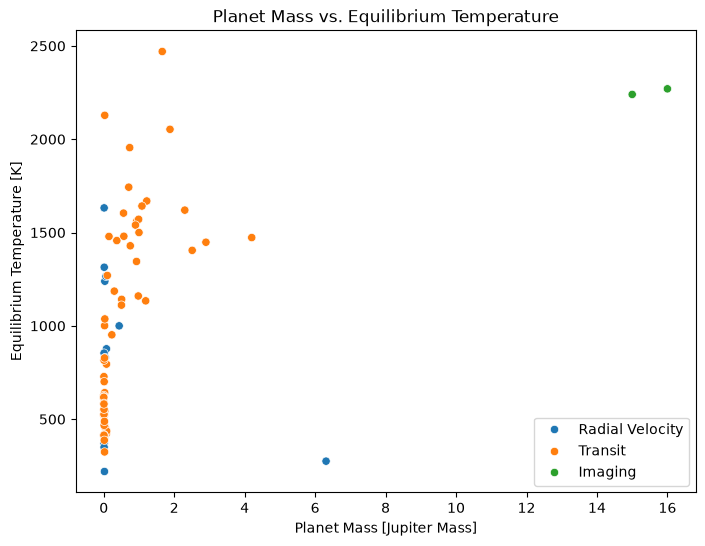

In [60]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=small_df,
    x='pl_bmassj',
    y='pl_eqt',
    hue='discoverymethod'
)

plt.title('Planet Mass vs. Equilibrium Temperature')
plt.xlabel('Planet Mass [Jupiter Mass]')
plt.ylabel('Equilibrium Temperature [K]')
plt.legend()
plt.show()

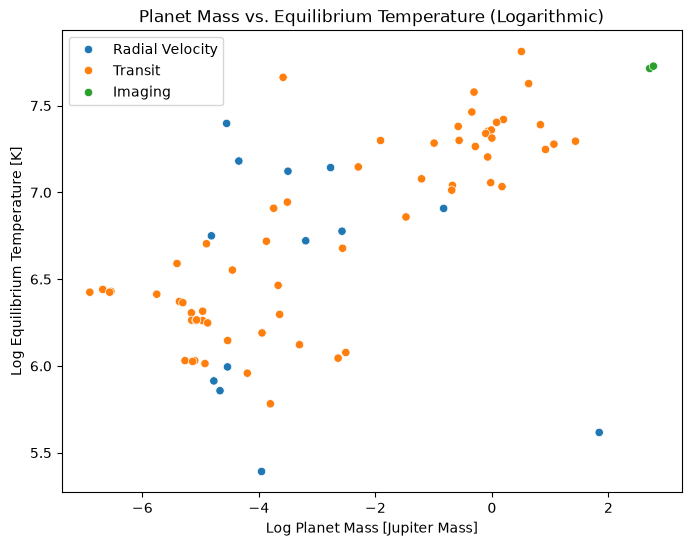

In [61]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=small_df,
    x=np.log(small_df['pl_bmassj']),
    y=np.log(small_df['pl_eqt']),
    hue='discoverymethod'
)

plt.title('Planet Mass vs. Equilibrium Temperature (Logarithmic)')
plt.xlabel('Log Planet Mass [Jupiter Mass]')
plt.ylabel('Log Equilibrium Temperature [K]')
plt.legend()
plt.show()

In [62]:
# planets discovered by imaging are pretty massive 

In [63]:
coldest = small_df[small_df['pl_bmassj'] > 5].sort_values('pl_eqt').iloc[0]

coldest

pl_name                eps Ind A b
hostname                 eps Ind A
discoverymethod    Radial Velocity
st_spectype                   K5 V
pl_eqt                       275.0
pl_bmassj                     6.31
Name: 597, dtype: object

The planet's name is 'esp Ind A b' and it is in index = [597]. Its equilibrium temperature is 275 K. It is 6.31 Jupiter masses. 
It is orbiting a K5 V star, whic is in a similar position to the sun on the HR diagram, but a bit cooler. 

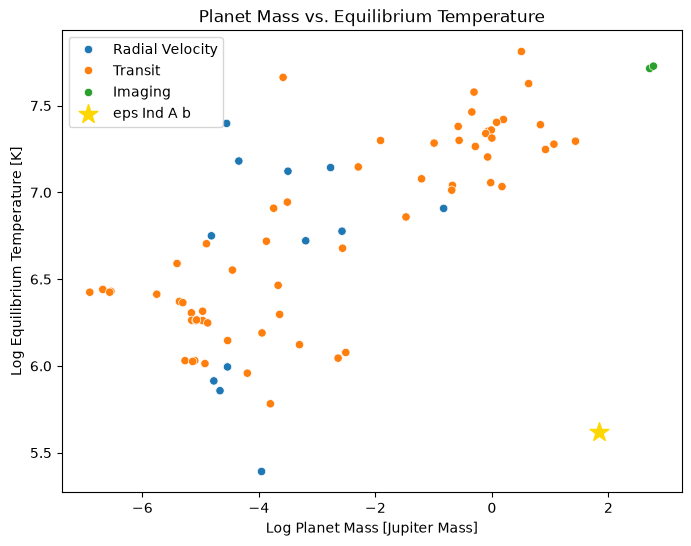

In [64]:
plt.figure(figsize=(8, 6))


sns.scatterplot(
    data=small_df,
    x=np.log(small_df['pl_bmassj']),
    y=np.log(small_df['pl_eqt']),
    hue='discoverymethod'
)

# Re-plot the coldest planet
plt.scatter(
    np.log(coldest['pl_bmassj']),
    np.log(coldest['pl_eqt']),
    color='gold',
    marker='*',
    s=200,
    label=coldest['pl_name']
)

plt.title('Planet Mass vs. Equilibrium Temperature')
plt.xlabel('Log Planet Mass [Jupiter Mass]')
plt.ylabel('Log Equilibrium Temperature [K]')
plt.legend()
plt.show()

- What is the title of this paper?
  A temperate super-Jupiter imaged with JWST in the mid-infrared
- Summarize the abstract to the best of your ability in your own words.
  JWST images revealed a giant exoplanet orbiting a K5V star named Eps Ind A, which affirmed hypotheses regarding the star's long-term radial velocity trend. 
- Does your answer match the exoplanet?
  Yes!
- What is special about the planet you found?
  It is probably the only giant planet in its system, and it is incredibly cold!
• Do the mass and equilibrium temperature match what the paper reported? If not, what
are the differences?
    Yes they match.